# [14.4] The JEPA Family (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part4_jepa_family/14.4_The_JEPA_Family_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part4_jepa_family/14.4_The_JEPA_Family_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Two representations predict each other perfectly. One encodes a moving object's colour and velocity; the other returns zero for every input. **Does zero prediction loss mean the representation learned the world?**

By the end of this notebook, you will have shown why latent prediction needs both a diversity check and a task-related probe, using five concrete view-pair fixtures and shuffled/collapsed controls. You will implement the shared mechanics, build the views yourself and see which factors survive. Our primary result is the five-modality probe and prediction matrix, with actual spectrogram, motion and retrieval examples alongside it.

The family resemblance is a question in embedding space: infer the representation of a target from a context. The exact encoders, masks, teacher updates, objectives and inference behavior differ substantially. An EMA teacher is useful in I-JEPA-like constructions but is **not a definition of every JEPA**. We test an EMA core as one organism, then fit small linear predictors with a fixed teacher to make the multi-modality comparison interpretable. These are tiny task-matched fixtures, not implementations or benchmark reproductions of all named papers.

Prerequisites: 14.1, matrix least squares, Fourier magnitude, simple gradient descent, and linear probes from chapter 11. Everything runs on CPU without downloads.

## Content & Learning Objectives

### 1️⃣ One predictive core, several choices

> ##### Learning Objectives
>
> - Implement masked context, target detachment, EMA updates and collapse diagnostics, identifying which choices are not universal.

### 2️⃣ Build five different pairs of views

> ##### Learning Objectives
>
> - Construct time-series, audio, motion/content, paired-text and vision-language teaching views with explicit targets.

### 3️⃣ Compare predictions with the same probe suite

> ##### Learning Objectives
>
> - Fit tiny latent predictors, decode known factors and contrast shuffled-pair and collapsed controls.

### 4️⃣ Intervene before claiming semantics

> ##### Learning Objectives
>
> - Ablate motion or content, inspect cross-modal retrieval and separate toy mechanics from named published models.

## Setup code

This study edition uses tiny CPU fixtures: no network, pretrained checkpoint, GPU or additional installation.

In [1]:
from pathlib import Path
import sys
import itertools
import numpy as np
import torch as t
import torch.nn.functional as F
import matplotlib.pyplot as plt
chapter = "chapter14_jepa_world_models"
section = "part4_jepa_family"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part4_jepa_family.tests as tests
MAIN = __name__ == "__main__"
device = t.device("cpu")
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ One predictive core, several choices

> ##### Learning Objectives
>
> - Implement masked context, target detachment, EMA updates and collapse diagnostics, identifying which choices are not universal.

Let $x_c$ and $x_t$ be two views of one example. An encoder $f_\theta$ maps context to a representation, a predictor $g_\phi$ maps that representation to a target representation, and a target encoder $f_{\bar\theta}$ supplies a detached target:
$$L=\operatorname{mean}\left[(g_\phi(f_\theta(x_c))-\mathrm{sg}[f_{\bar\theta}(x_t)])^2\right].$$
An EMA update is $\bar\theta\leftarrow m\bar\theta+(1-m)\theta$. It is a parameter update, not an optimizer gradient through the target branch. The next four exercises make those statements executable, including a gradient test that a numerically correct scalar loss alone would miss.

For the core mask fixture, `x` is `(batch,tokens,features)` and `visible` is `(batch,tokens)`. We use masked mean pooling: invisible tokens contribute neither to numerator nor denominator. All-masked examples are errors. Actual published transformer encoders can preserve token order and use mask-position tokens; mean pooling cannot, so we do not use it as a claim about a paper architecture.

### Exercise - implement `masked_mean`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the masked average with shape `(batch,features)`. A zero-filled masked token must not dilute the mean: that would leak the number of hidden tokens into feature scale. Keep the operation differentiable for visible values.

In [2]:
def masked_mean(tokens, visible):
    weights = visible.to(tokens.dtype)[..., None]
    count = weights.sum(dim=1)
    if t.any(count == 0):
        raise ValueError("each context needs a visible token")
    return (tokens * weights).sum(dim=1) / count


tests.test_masked_mean(masked_mean)

All tests in test_masked_mean passed!


<details><summary>Hint</summary>

Multiply by a float visibility mask and divide by its count, not total sequence length.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_masked_mean passed!`. The pooled feature is `[3,5]`; the hidden token receives zero gradient.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `jepa_mse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the MSE latent target loss with stop-gradient on the target only. Keep gradients through predictions. This exact exercise belongs to our EMA-core organism; the later language reading notes explain why it must not be declared universal.

In [3]:
def jepa_mse(prediction, target):
    return ((prediction - target.detach())**2).mean()


tests.test_jepa_mse(jepa_mse)

All tests in test_jepa_mse passed!


<details><summary>Hint</summary>

Detach the target before subtraction. A `no_grad` block around the entire loss would also kill the predictor gradient.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_jepa_mse passed!`. Loss is `2.5`, predictor gradient `[-1,2]`, target gradient absent.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `ema_update`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Update corresponding tensors in place and without constructing an autograd graph. Here the teacher/student are lists of identically shaped parameters. Validate momentum. EMA momentum 1 freezes a teacher; momentum 0 copies the current student.

In [4]:
def ema_update(teacher, student, momentum):
    if not 0 <= momentum <= 1:
        raise ValueError("momentum must be in [0,1]")
    with t.no_grad():
        for target, source in zip(teacher, student, strict=True):
            target.mul_(momentum).add_(source, alpha=1-momentum)


tests.test_ema_update(ema_update)

All tests in test_ema_update passed!


<details><summary>Hint</summary>

Use `no_grad` only for the parameter assignment.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_ema_update passed!`. At momentum `.75`, teacher `[2,4]` becomes `[3,3]`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `collapse_statistics`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return per-coordinate population variance and the effective rank of centered covariance energy. Constant nonzero vectors are collapsed too. If all energy is zero, return effective rank zero instead of dividing by zero. Rank is a diagnostic, not a semantic score.

In [5]:
def collapse_statistics(embeddings):
    centered = embeddings - embeddings.mean(axis=0, keepdims=True)
    variance = np.mean(centered**2, axis=0)
    singular = np.linalg.svd(centered, compute_uv=False)
    energy = singular**2
    if energy.sum() < 1e-20:
        return variance, 0.0
    p = energy[energy > 1e-20] / energy.sum()
    return variance, float(np.exp(-np.sum(p * np.log(p))))


tests.test_collapse_statistics(collapse_statistics)

All tests in test_collapse_statistics passed!


<details><summary>Hint</summary>

The covariance eigenvalues are proportional to squared singular values of the centered embedding matrix.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_collapse_statistics passed!`. Constant embeddings have variance/rank zero; isotropic two-coordinate embeddings have rank two.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

In [6]:
t.manual_seed(4)
encoder = t.nn.Linear(4,2,bias=False,device="cpu")
teacher = t.nn.Linear(4,2,bias=False,device="cpu")
teacher.load_state_dict(encoder.state_dict())
predictor = t.nn.Linear(2,2,bias=False,device="cpu")
x=t.tensor([[1.,0.,1.,0.],[0.,1.,0.,1.],[1.,1.,1.,1.]])
optimizer=t.optim.SGD(list(encoder.parameters())+list(predictor.parameters()),lr=.05)
loss=jepa_mse(predictor(encoder(x)),teacher(x));optimizer.zero_grad();loss.backward();optimizer.step()
ema_update(list(teacher.parameters()),list(encoder.parameters()),.9)
print("finite one-update loss:",round(float(loss.detach()),6))
print("collapsed target loss:",float(jepa_mse(t.zeros(3,2),t.zeros(3,2))))

finite one-update loss: 0.051244
collapsed target loss: 0.0


## Summary of 1️⃣

A zero loss can be produced by zero information. A detached teacher changes gradient routing, while EMA changes its later parameter value. Neither scalar fit nor representation rank alone says what information is present.

# 2️⃣ Build five different pairs of views

> ##### Learning Objectives
>
> - Construct time-series, audio, motion/content, paired-text and vision-language teaching views with explicit targets.

Now make the data genuinely different. The same two numeric factors index each fixture, but their meanings differ: intercept/slope, two tone amplitudes, content/motion, counts of two words, or two visual-channel intensities. These are deliberately recoverable factors, not a universal semantic ground truth across modalities.

Every adapter returns a context vector and a target vector with four coordinates. Context and target are paired views, not necessarily adjacent tokens. Four-dimensional handcrafted inputs are the boundary of our small linear organism. We fit a two-dimensional fixed-teacher embedding and a context-to-target predictor. The point is to understand what a target makes predictable and how the control should fail; training a deep representation from raw data remains pending.

### Exercise - implement `time_views`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Build eight-step linear time series. Return the first four samples as context and the last four as target, both `(batch,4)`. This is a causal future mask: no future sample enters the context. The predictor must extrapolate, not copy arbitrary hidden positions.

In [7]:
def time_views(intercept, slope):
    times = np.arange(8, dtype=float)
    series = np.asarray(intercept)[:, None] + np.asarray(slope)[:, None] * times
    return series[:, :4], series[:, 4:]


tests.test_time_views(time_views)

All tests in test_time_views passed!


<details><summary>Hint</summary>

Broadcast factors against `np.arange(8)`.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_time_views passed!`. Intercept 2 and slope .5 yield target `[4,4.5,5,5.5]`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `audio_views`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Generate two phase-shifted views of a 32-sample two-tone signal, then return normalized Fourier magnitudes at four bins. Bins 3 and 7 carry the amplitudes; bins 10 and 12 are absent. A phase shift preserves these magnitudes. This is a tiny spectral view-prediction analogue, not mel-spectrogram A-JEPA training.

In [8]:
def audio_views(amplitude1, amplitude2):
    time = np.arange(32, dtype=float) / 32
    views = []
    for phase in [0., np.pi/3]:
        signal = np.asarray(amplitude1)[:,None]*np.sin(2*np.pi*3*time+phase) + np.asarray(amplitude2)[:,None]*np.sin(2*np.pi*7*time+phase)
        magnitude = np.abs(np.fft.rfft(signal, axis=1)) / 16
        views.append(magnitude[:, [3,7,10,12]])
    return tuple(views)


tests.test_audio_views(audio_views)

All tests in test_audio_views passed!


<details><summary>Hint</summary>

A unit-amplitude sine at a non-DC FFT bin has magnitude `N/2`; divide by 16.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_audio_views passed!`. The spectral factors survive phase shift; empty-bin magnitudes are numerical zero.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `motion_content_views`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Represent a one-dimensional moving marker with two observed positions, a persistent content value and a constant channel. Predict the next pair of positions and persistent content. Content is also the initial position here, so name this coupling when interpreting probes. MC-JEPA itself jointly learns optical flow and content features; these four scalars do not implement its optical-flow objective.

In [9]:
def motion_content_views(content, velocity):
    content, velocity = np.asarray(content), np.asarray(velocity)
    context = np.stack([content, content+velocity, content, np.ones_like(content)],axis=1)
    target = np.stack([content+2*velocity, content+3*velocity, content, np.ones_like(content)],axis=1)
    return context, target


tests.test_motion_content_views(motion_content_views)

All tests in test_motion_content_views passed!


<details><summary>Hint</summary>

Each later position is initial position plus elapsed time times velocity.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_motion_content_views passed!`. A left-moving marker has context positions `2,1.5` and target positions `1,.5`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `text_views`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Construct count embeddings for paired phrases “R red and B blue” and “B blue with R red.” We represent the role change by swapping the first two feature positions. This keeps exact lexical count targets visible. It is not an LLM and cannot establish reasoning or syntax understanding.

In [10]:
def text_views(count_red, count_blue):
    count_red, count_blue = np.asarray(count_red), np.asarray(count_blue)
    context = np.stack([count_red, count_blue, count_red+count_blue, np.ones_like(count_red)],axis=1)
    target = np.stack([count_blue, count_red, count_red+count_blue, np.ones_like(count_red)],axis=1)
    return context, target


tests.test_text_views(text_views)

All tests in test_text_views passed!


<details><summary>Hint</summary>

Keep example order fixed; swapping feature roles is not shuffling examples.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_text_views passed!`. The first phrase pair maps `[2,3,5,1]` to `[3,2,5,1]`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `visual_language_views`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Build two-channel 4×4 images: red intensity occupies the left half, blue intensity the right. The fixed query is “report the red and blue intensities.” The target is a continuous numeric answer embedding, not pixels or generated words. The context contains channel means, each half the corresponding intensity.

In [11]:
def visual_language_views(red, blue):
    red, blue = np.asarray(red), np.asarray(blue)
    images = np.zeros((len(red),2,4,4))
    images[:,0,:,:2] = red[:,None,None]
    images[:,1,:,2:] = blue[:,None,None]
    context = np.stack([images[:,0].mean((1,2)), images[:,1].mean((1,2)), np.ones_like(red), np.zeros_like(red)],axis=1)
    answer_embeddings = np.stack([red, blue, red-blue, np.ones_like(red)],axis=1)
    return context, answer_embeddings


tests.test_visual_language_views(visual_language_views)

All tests in test_visual_language_views passed!


<details><summary>Hint</summary>

Two of four columns are occupied, so a channel mean divides the intensity by two.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_visual_language_views passed!`. For intensities .8 and .2, the image means are .4 and .1; answer features are `[.8,.2,.6,1]`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

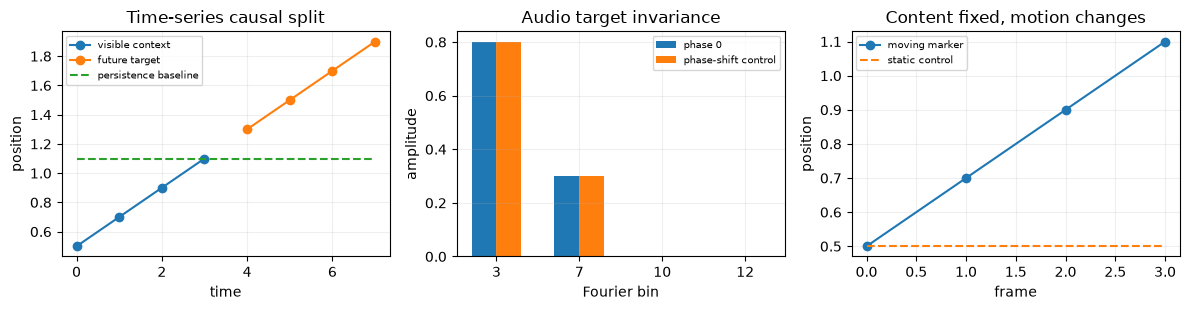

In [12]:
ctime,ytime=time_views(np.array([.5]),np.array([.2]))
caudio,yaudio=audio_views(np.array([.8]),np.array([.3]))
cmotion,ymotion=motion_content_views(np.array([.5]),np.array([.2]))
fig,axs=plt.subplots(1,3,figsize=(12,3.2))
axs[0].plot(range(4),ctime[0],"o-",label="visible context");axs[0].plot(range(4,8),ytime[0],"o-",label="future target")
axs[0].plot(range(8),np.repeat(ctime[0,-1],8),"--",label="persistence baseline")
axs[0].set(xlabel="time",ylabel="position",title="Time-series causal split")
axs[1].bar(np.arange(4)-.15,caudio[0],.3,label="phase 0");axs[1].bar(np.arange(4)+.15,yaudio[0],.3,label="phase-shift control")
axs[1].set(xticks=range(4),xticklabels=[3,7,10,12],xlabel="Fourier bin",ylabel="amplitude",title="Audio target invariance")
axs[2].plot(range(4),np.r_[cmotion[0,:2],ymotion[0,:2]],"o-",label="moving marker")
axs[2].plot(range(4),np.repeat(cmotion[0,0],4),"--",label="static control")
axs[2].set(xlabel="frame",ylabel="position",title="Content fixed, motion changes")
for ax in axs:ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.tight_layout();plt.show()

## Summary of 2️⃣

Mask direction and target construction carry scientific assumptions. Future samples are not text views; phase-invariant audio is not optical flow; predicting an answer embedding is not autoregressive text generation. Our fixtures make those distinctions visible.

# 3️⃣ Compare predictions with the same probe suite

> ##### Learning Objectives
>
> - Fit tiny latent predictors, decode known factors and contrast shuffled-pair and collapsed controls.

Use one predictor recipe for all adapters. Let a frozen target encoder be $E\in\mathbb R^{4\times2}$, so $Y=x_t E$. Fit an affine predictor from context to $Y$ by least squares. This exactly solves a restricted latent-MSE learning problem; it does not learn the encoder. We already exercised a gradient-based EMA update above, separately. Keeping those two experiments separate avoids pretending that a fixed-teacher regression is end-to-end JEPA training.

The same probe suite asks whether the two original factors can be linearly recovered from predicted target embeddings. Fit on alternating rows, report on the other rows, and preserve those as **public fitting/check fixtures**, not an independent dataset. Compare aligned pairs, shuffled fitting pairs, and a collapsed constant representation. Normalize mean squared error by the factor variance on the check rows: a constant mean predictor has normalized error around one; zero is exact recovery.

### Exercise - implement `fit_affine`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit an affine linear map, returning `(input_features+1,target_features)`. This operation is used both for the target predictor and the downstream factor probe. Keep those fitted maps distinct: the factor probe uses labels, while the target predictor uses teacher embeddings.

In [13]:
def fit_affine(inputs, targets):
    design = np.c_[inputs, np.ones(len(inputs))]
    return np.linalg.lstsq(design, targets, rcond=None)[0]


tests.test_fit_affine(fit_affine)

All tests in test_fit_affine passed!


<details><summary>Hint</summary>

Append an intercept column of ones and solve least squares.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_fit_affine passed!`. The affine fixture recovers both slopes and the nonzero intercept.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `normalized_probe_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one normalized MSE for each factor. Aggregate across examples only. Reject zero-variance factors because there is no meaningful variance normalization for them. Prediction error and probe error are different: collapsed embeddings can achieve zero latent MSE and still fail this factor test.

In [14]:
def normalized_probe_error(prediction, truth):
    mse = np.mean((prediction-truth)**2, axis=0)
    variance = np.var(truth, axis=0)
    if np.any(variance < 1e-12):
        raise ValueError("probe factors must vary")
    return mse / variance


tests.test_normalized_probe_error(normalized_probe_error)

All tests in test_normalized_probe_error passed!


<details><summary>Hint</summary>

Compute featurewise variances, not a single global variance.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_normalized_probe_error passed!`. The zero predictor has normalized error one for each centered test factor.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

In [15]:
factors=np.array(list(itertools.product(np.linspace(.2,1.,8),repeat=2)))
fit=np.arange(len(factors))%2==0
check=~fit
E=np.array([[1.,.2],[-.3,1.],[.5,-.4],[.1,.2]])
adapters={"time":time_views,"audio":audio_views,"motion/content":motion_content_views,"paired text":text_views,"vision→answer":visual_language_views}
rows=[];ranks=[];latent_errors=[];retrieval_pairs={}
for name,adapter in adapters.items():
    adapter_factors = np.rint((factors-.2)*7/.8)+1 if name == "paired text" else factors
    c,y=adapter(*adapter_factors.T);teacher_y=y@E
    affine=fit_affine(c[fit],teacher_y[fit])
    predicted=np.c_[c,np.ones(len(c))]@affine
    shuffle=np.random.default_rng(23).permutation(fit.sum())
    bad=fit_affine(c[fit],teacher_y[fit][shuffle])
    bad_pred=np.c_[c,np.ones(len(c))]@bad
    outputs=[]
    for representation in [predicted,bad_pred,np.zeros_like(predicted)]:
        probe=fit_affine(representation[fit],factors[fit])
        decoded=np.c_[representation[check],np.ones(check.sum())]@probe
        outputs.append(normalized_probe_error(decoded,factors[check]).mean())
    # A shuffled teacher can remain an invertible linear map: audit direct target prediction too.
    latent_errors.append([np.mean((predicted[check]-teacher_y[check])**2),np.mean((bad_pred[check]-teacher_y[check])**2),0.])
    rows.append(outputs);ranks.append(collapse_statistics(predicted)[1]);retrieval_pairs[name]=(predicted[check],teacher_y[check])
rows=np.asarray(rows);latent_errors=np.asarray(latent_errors)
print("probe normalized errors [aligned, shuffled-fit, collapsed]:")
for name,row in zip(adapters,rows):print(name,np.round(row,4))
print("target latent MSE [aligned, shuffled-fit, collapsed target]:")
print(np.round(latent_errors,4))

probe normalized errors [aligned, shuffled-fit, collapsed]:
time [0.  0.  1.1]
audio [0.  0.  1.1]
motion/content [0.  0.  1.1]
paired text [0.  0.  1.1]
vision→answer [0.  0.  1.1]
target latent MSE [aligned, shuffled-fit, collapsed target]:
[[0.     2.3604 0.    ]
 [0.     0.0868 0.    ]
 [0.     0.5547 0.    ]
 [0.     7.806  0.    ]
 [0.     0.2014 0.    ]]


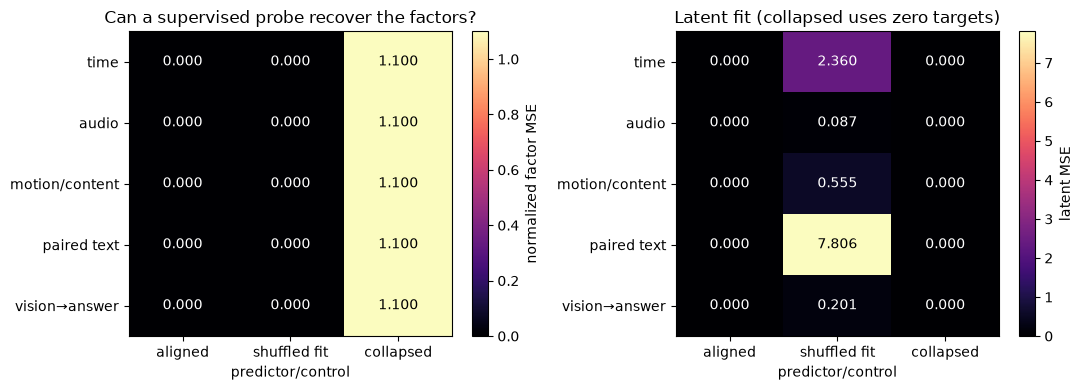

In [16]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,values,title in [(axs[0],rows,"Can a supervised probe recover the factors?"),(axs[1],latent_errors,"Latent fit (collapsed uses zero targets)")]:
    im=ax.imshow(values,aspect="auto",cmap="magma",vmin=0)
    ax.set(xticks=range(3),xticklabels=["aligned","shuffled fit","collapsed"],yticks=range(5),yticklabels=list(adapters),title=title,xlabel="predictor/control")
    for i in range(5):
        for j in range(3):ax.text(j,i,f"{values[i,j]:.3f}",ha="center",va="center",color="white" if values[i,j]<values.max()*.5 else "black")
    fig.colorbar(im,ax=ax,label="normalized factor MSE" if ax is axs[0] else "latent MSE")
fig.tight_layout();plt.show()

<details><summary>Help - why might the shuffled control pass the probe?</summary>

The executed reference gives normalized probe errors `[0,0,1.1]` in every row. The collapsed predictor uses the fitting-set mean, while the alternating check grid has a shifted mean, hence `1.1` rather than exactly `1`. In contrast, aligned latent-target MSE is numerical zero in every modality, and shuffled-pair latent MSE is positive. A linear predictor fit to shuffled pairs can still be an invertible map of the two input factors. A new supervised probe can undo that map. Therefore **a passing probe does not establish correct target prediction**. Look at the right panel, which compares predicted embeddings to their actual paired teacher targets. Conversely the collapsed-target column has zero latent loss by definition, but cannot recover varying factors. These two failures are complementary, not contradictory.

The fit/check split alternates the second factor's values; both subsets contain public examples from the same explicit grid. It tests interpolation of this finite family, not a generalization benchmark or semantic equivalence across modalities.

</details>

## Summary of 3️⃣

Correct target matching, diversity and probe decodability answer different questions. A robust claim needs all three plus a control aligned to the proposed mechanism.

# 4️⃣ Intervene before claiming semantics

> ##### Learning Objectives
>
> - Ablate motion or content, inspect cross-modal retrieval and separate toy mechanics from named published models.

A representation can preserve a factor that the downstream task never uses. For the motion fixture, remove velocity by replacing the second position with the first. For a content intervention, shift the content channel while leaving positions intact. These deliberately off-manifold interventions test the handcrafted interface; a learned representation would require additional counterfactual checks.

For vision-language prediction, compare each predicted answer embedding against all candidate teacher answer embeddings. Nearest Euclidean target retrieval is enough for the tiny fixture. It is not cosine retrieval in a released VL-JEPA, and we do not invoke a text decoder. The control permutes the candidate answer assignment, preserving embedding geometry while breaking semantic pairing.

### Exercise - implement `ablate_motion`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Remove the two-frame displacement while preserving the first position, persistent content and constant channel. Return a copy. This is the specific motion intervention in this organism, not a claim that coordinate one is a motion neuron in MC-JEPA.

In [17]:
def ablate_motion(context):
    out=np.array(context,copy=True)
    out[:,1]=out[:,0]
    return out


tests.test_ablate_motion(ablate_motion)

All tests in test_ablate_motion passed!


<details><summary>Hint</summary>

Zero displacement means equal successive positions.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_ablate_motion passed!`. The intervention removes velocity while preserving content.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `retrieval_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the full query×candidate squared-distance matrix and top-one accuracy. Ties go to the earliest candidate. Do not normalize or rescale each query separately: the target prediction and candidate embeddings share a defined coordinate system.

In [18]:
def retrieval_accuracy(predicted, candidates, correct_indices):
    distance=((predicted[:,None,:]-candidates[None,:,:])**2).sum(axis=-1)
    retrieved=np.argmin(distance,axis=1)
    return float(np.mean(retrieved==correct_indices)), distance


tests.test_retrieval_accuracy(retrieval_accuracy)

All tests in test_retrieval_accuracy passed!


<details><summary>Hint</summary>

Broadcast a query axis against a candidate axis and sum only over embedding coordinates.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_retrieval_accuracy passed!`. The two-query fixture retrieves indices 1 and 0 with accuracy one.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

vision-answer top-one: 1.0 permuted-answer control: 0.0
motion target MSE aligned/ablated: 0.0 2.736429


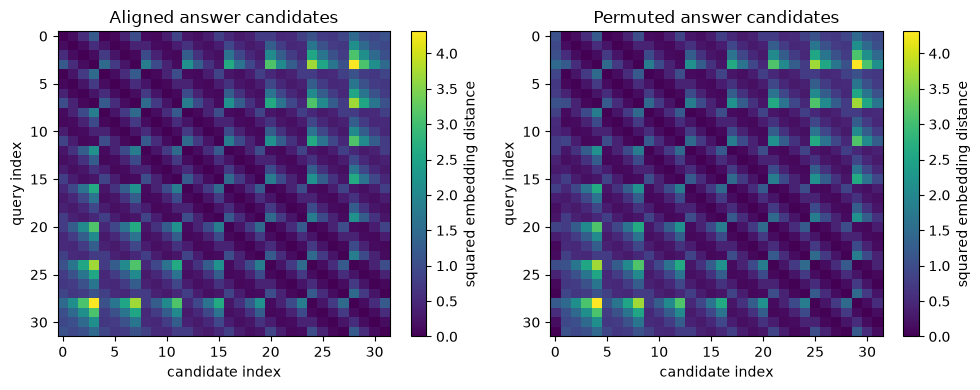

In [19]:
p,y=retrieval_pairs["vision→answer"]
accuracy,dist=retrieval_accuracy(p,y,np.arange(len(p)))
wrong=np.roll(np.arange(len(p)),1)
bad_accuracy,bad_dist=retrieval_accuracy(p,y[wrong],np.arange(len(p)))
c,y_motion=motion_content_views(*factors.T)
wm=fit_affine(c[fit],(y_motion@E)[fit])
true_predictions=np.c_[c,np.ones(len(c))]@wm
ablated_predictions=np.c_[ablate_motion(c),np.ones(len(c))]@wm
target=y_motion@E
print("vision-answer top-one:",accuracy,"permuted-answer control:",bad_accuracy)
print("motion target MSE aligned/ablated:",round(float(np.mean((true_predictions-target)**2)),6),round(float(np.mean((ablated_predictions-target)**2)),6))
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,d,title in [(axs[0],dist,"Aligned answer candidates"),(axs[1],bad_dist,"Permuted answer candidates")]:
    im=ax.imshow(d,cmap="viridis",aspect="auto");fig.colorbar(im,ax=ax,label="squared embedding distance")
    ax.set(xlabel="candidate index",ylabel="query index",title=title)
fig.tight_layout();plt.show()

## Try it yourself

Change the audio phase from `π/3` to `π/2` inside your function, then add a third tone at bin 10 only in the target view. Predict which probe and loss changes. Is a target-only random amplitude predictable from context? Keep the factor labels fixed and explain why no larger predictor can remove irreducible uncertainty.

In [20]:
play_context, play_target=audio_views(np.array([.8]),np.array([.3]))
play_target[:,2]=.6  # genuinely new target-only tone
baseline_context,baseline_target=audio_views(*factors.T)
audio_predictor=fit_affine(baseline_context[fit],(baseline_target@E)[fit])
play_prediction=np.c_[play_context,np.ones(1)]@audio_predictor
print("new-tone latent squared error:",float(np.mean((play_prediction-play_target@E)**2)))

new-tone latent squared error: 0.07380000000000005


## Interpreting the result and limitations

The actual vision-answer retrieval is `1.0`, versus `0.0` under cyclic answer permutation. Removing displacement raises motion target MSE from numerical zero to `2.736429`. The target-only tone play yields latent squared error `0.0738`. The linear view maps make every pair exactly predictable from two factors. A successful factor probe therefore confirms this constructed organism's recoverability. It does not establish that end-to-end JEPA training discovers semantic factors or invariance on natural data. Fixed-target regression and the one-update EMA fixture are distinct evidence layers.

## Named-method bridge and reading-only variants

| Method | What is implemented here | What remains reading/native work |
|---|---|---|
| Time-series JEPA | Causal future-view time-series prediction | Time-series encoder training and downstream tasks. “T-JEPA” is ambiguous: [TS-JEPA / Joint Embeddings Go Temporal](https://openreview.net/pdf?id=FIdbozebmy) is distinct from the [2026 temporal remote-sensing T-JEPA](https://arxiv.org/abs/2610.05731). Neither name is silently identified with this four-value adapter. |
| Audio JEPA | Fourier-magnitude paired views and target loss | [A-JEPA](https://arxiv.org/abs/2311.15830) uses visible spectrogram patches, an EMA target and curriculum masking; no mel encoder or audio benchmark runs here. |
| MC-JEPA | Separate content and displacement interventions | [MC-JEPA](https://arxiv.org/abs/2307.12698) combines optical-flow and self-supervised content objectives; that joint training is pending. |
| LLM-JEPA | A paired-text count analogue | [LLM-JEPA](https://arxiv.org/abs/2509.14252) adds embedding-space learning to language training. Our detached-MSE EMA organism is not a claim that its target-update/objective design is identical. |
| VL-JEPA | Image features predict an answer embedding; retrieval | [VL-JEPA](https://arxiv.org/abs/2512.10942) predicts continuous target-text embeddings and can selectively decode text; no pretrained visual/text encoder or decoder is executed here. |

The remaining methods are **reading-only**, not extra implementations:

- [3D-JEPA](https://arxiv.org/abs/2409.15803) moves latent prediction to 3D representations; inspect spatial grouping and target definition before porting masks.
- [US-JEPA](https://arxiv.org/abs/2602.19322) concerns medical ultrasound. Its SALT objective uses a frozen domain-specific teacher rather than an EMA teacher; our EMA default is not universal or clinical evidence.
- [BiJEPA](https://arxiv.org/abs/2603.00049) studies bidirectional symmetric representation learning. Directionality of view prediction is a design choice, not a cosmetic rename.
- [MJEPA](https://arxiv.org/abs/2606.25225) concerns audio-visual learning. Cross-modal synchronization and missing-modality controls would be additional requirements.
- [Demo-JEPA official repository](https://github.com/banban3forever/Demo-JEPA) describes one-shot cross-embodiment imitation; its world-model and demonstration interfaces are not replaced by our paired scalars.
- [SparseJEPA](https://arxiv.org/abs/2504.16140) adds sparse representation learning to JEPA. A sparsity penalty and grouping analysis require a separate implementation and control; a low effective rank alone is not evidence for its mechanism.

# ☆ Bonus

**Anomaly question:** why can shuffled fitting yield a poor target predictor but a good downstream probe? Construct an invertible wrong map by hand, then show that the probe can invert it. What additional observation would establish a correct cross-view relationship?

**Changed-condition prediction:** train on positive slope only, then evaluate negative slopes without refitting. This changes the factor support, rather than a random seed. Predict whether the linear time-series organism extrapolates, and distinguish that analytic expectation from natural-data transfer.